--- MODEL EVALUATION ---
Accuracy: 0.5614
F1-Score: 0.5611

Confusion matrix successfully saved as 'confusion_matrix.png'!


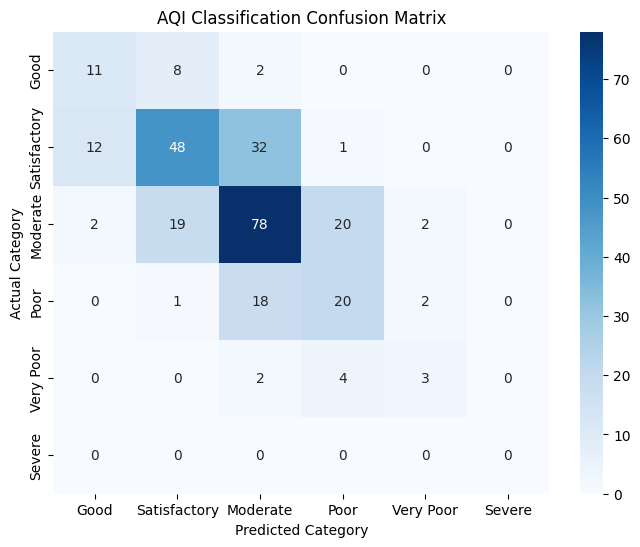

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. LOADING THE DATA
X = pd.read_csv('/content/X_features.csv')
y_raw = pd.read_csv('/content/y_target.csv')

# Extract the target column as a 1D Series.
y = y_raw.AQI

# 2. CONVERTING THE TARGET (The Bucket Sorter)
def categorize_aqi(aqi_value):
    if aqi_value <= 50:
        return "Good"
    elif aqi_value <= 100:
        return "Satisfactory"
    elif aqi_value <= 200:
        return "Moderate"
    elif aqi_value <= 300:
        return "Poor"
    elif aqi_value <= 400:
        return "Very Poor"
    else:
        return "Severe"

y_categorical = y.apply(categorize_aqi)

# 3. SPLITTING THE DATA & TRAIN THE MODEL

# Randomly hide 20% of the data to test the model later
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Initializing and training the Decision Tree
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# Making guesses on the 20% hidden test data
y_pred = clf.predict(X_test)

# 4. THE GRADING & VISUALIZATION
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted')

print("--- MODEL EVALUATION ---")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-Score: {f1:.4f}")

# Defining the labels in standard AQI order for the matrix
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]

# Calculating and drawing the Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('AQI Classification Confusion Matrix')

# Automatically saving the image for GitHub BEFORE displaying it
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=300)
print("\nConfusion matrix successfully saved as 'confusion_matrix.png'!")

plt.show()